In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from urllib.parse import urlsplit

df = pd.read_csv("../data/raw/url_dataset.csv")
n_start = len(df)

- Domain
- URL
- URL Length
- TLD
- IsHTTPS
- Label

Keep all above columns
Turn Label 1 to 0 and vice versa (reverse the labels)

In [3]:
print("Before: ", df["label"].value_counts().to_dict())

df["label"] = 1 - df["label"]

df = df[["Domain", "URL", "URLLength", "TLD", "IsHTTPS", "label"]]
df.rename(columns={"URL":"url", "URLLength":"urlLength", "TLD":"tld", "IsHTTPS":"isHttp"})

print("After: ", df["label"].value_counts().to_dict())
assert set(df["label"].unique()) == {0, 1}

df.to_csv("url_processed_dataset.csv", index=False)
print(df.shape)
df.head()

Before:  {1: 134850, 0: 100945}
After:  {0: 134850, 1: 100945}
(235795, 6)


,Domain,URL,URLLength,TLD,IsHTTPS,label
0,www.southbankmosaics.com,https://www.southbankmosaics.com,31,com,1,0
1,www.uni-mainz.de,https://www.uni-mainz.de,23,de,1,0
2,www.voicefmradio.co.uk,https://www.voicefmradio.co.uk,29,uk,1,0
3,www.sfnmjournal.com,https://www.sfnmjournal.com,26,com,1,0
4,www.rewildingargentina.org,https://www.rewildingargentina.org,33,org,1,0


In [4]:
# Class Balance
label = (df["label"].value_counts().to_dict())

values = list(label.values())
total = values[0] + values[1]

print(f"Legitimate: {(values[0]/total) * 100}%")
print(f"Phishing: {(values[1]/total) * 100}%")
    

Legitimate: 57.189507835195826%
Phishing: 42.810492164804174%


In [5]:
# remove duplicate url's

# url that appears in both label is contradictory
labels_per_url = df.groupby("URL")["label"].nunique()
conflicting = labels_per_url[labels_per_url > 1].index
df = df[~df["URL"].isin(conflicting)]

df = df.drop_duplicates(subset="URL").reset_index(drop=True)
print(f"Start: {n_start} | conflicting URLs dropped: {len(conflicting)} | after dedup: {len(df)}")
print(df["label"].value_counts())

norm = df["URL"].str.lower().str.rstrip("/")
print("Near-duplicates (case/trailing slash):", norm.duplicated().sum())

df.to_csv("url_cleaned.csv", index=False)
print("Saved to cleaned csv...")

Start: 235795 | conflicting URLs dropped: 0 | after dedup: 235370
label
0    134850
1    100520
Name: count, dtype: int64
Near-duplicates (case/trailing slash): 1165
Saved to cleaned csv...


In [17]:
def path_len(u):
    try:
        p = urlsplit(u if "://" in u else "http://" + u)
    except ValueError:
        return np.nan
    return len(p.path.rstrip("/")) + len(p.query) + len(p.fragment)

s = df["URL"]
df["n_dots"]    = s.str.count(r"\.")
df["n_digits"]  = s.str.count(r"\d")
df["n_special"] = s.str.count(r"[^A-Za-z0-9]")
df["path_len"]  = [path_len(u) for u in s]
df["has_path"]  = df["path_len"] > 0
df["has_www"]   = s.str.contains(r"^(?:https?://)?www\.", case=False, regex=True)
df["class"]     = df["label"].map({0: "legitimate", 1: "phishing"})

cols = ["URLLength", "n_dots", "n_digits", "n_special", "path_len"]
df.groupby("class")[cols].agg(["mean", "median", "max"]).T

class              legitimate   phishing
URLLength mean      45.702845  26.228610
          median    34.000000  26.000000
          max     6097.000000  57.000000
n_dots    mean       2.384889   2.161661
          median     2.000000   2.000000
          max       99.000000   5.000000
n_digits  mean       4.336222   0.050597
          median     0.000000   0.000000
          max     2011.000000   8.000000
n_special mean       7.649552   5.244865
          median     6.000000   5.000000
          max      775.000000  11.000000
path_len  mean      13.834779   0.000000
          median     0.000000   0.000000
          max     6065.000000   0.000000

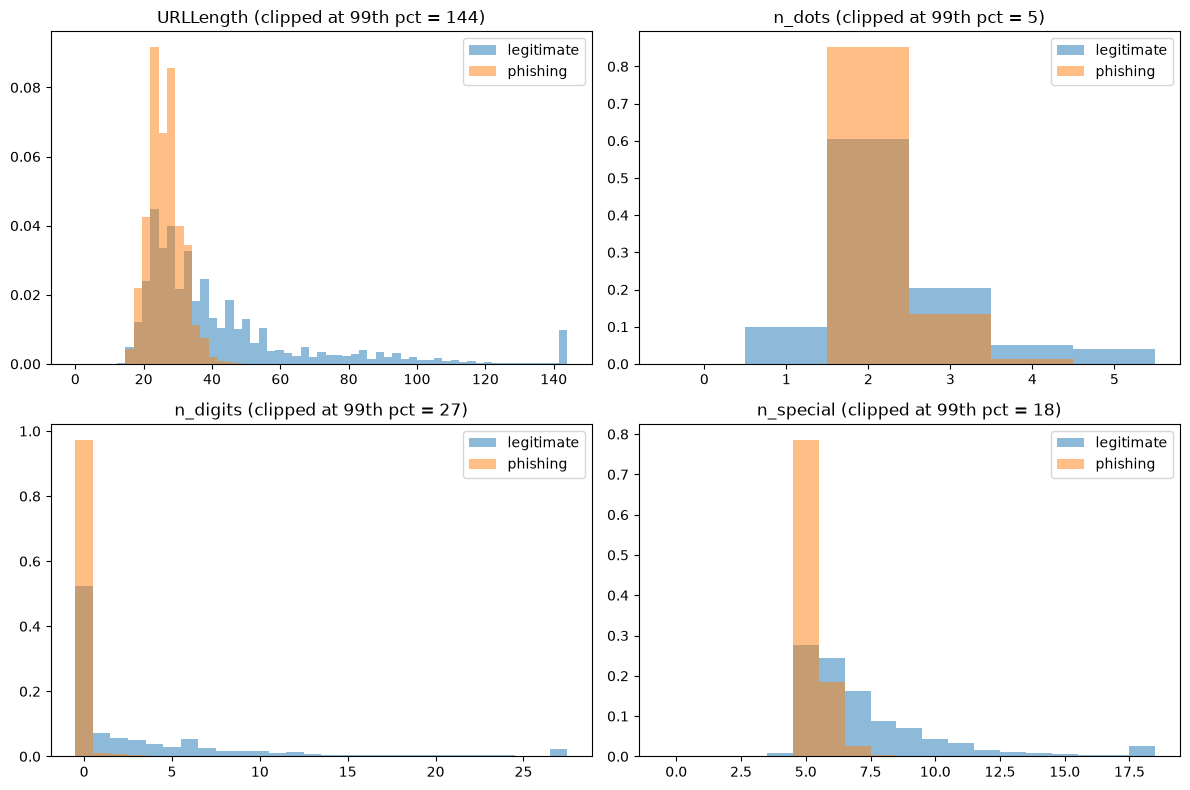

In [18]:
plot_cols = ["URLLength", "n_dots", "n_digits", "n_special"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, plot_cols):
    hi = df[col].quantile(0.99)
    bins = np.linspace(0, hi, 60) if col == "URLLength" else np.arange(0, hi + 2) - 0.5
    for name, g in df.groupby("class"):
        ax.hist(g[col].clip(upper=hi), bins=bins, alpha=0.5, density=True, label=name)
    ax.set_title(f"{col} (clipped at 99th pct = {hi:.0f})")
    ax.legend()
plt.tight_layout()
plt.savefig("eda_distributions.png", dpi=150)
plt.show()

In [21]:
cc = Counter()
for u in df["URL"]:
    cc.update(u)
total = sum(cc.values())
freq = pd.Series(cc).sort_values(ascending=False)
cov = freq.cumsum() / total

print("Unique characters:", len(cc))
odd = {c: n for c, n in cc.items() if ord(c) < 32 or ord(c) > 126}
print("Non-printable / non-ASCII chars:", len(odd), "| occurrences:", sum(odd.values()))
for k in (40, 60, 70, 80, 95):
    if k <= len(freq):
        print(f"Top {k:>3} chars cover {cov.iloc[k-1]:.5%}")

df["has_non_ascii"] = df["URL"].map(lambda u: any(ord(c) > 126 for c in u))
print(df.groupby("class")["has_non_ascii"].mean())

# For choosing max sequence length later
print(df.groupby("class")["URLLength"].quantile([.90, .95, .99]).unstack())

Unique characters: 71
Non-printable / non-ASCII chars: 12 | occurrences: 64
Top  40 chars cover 99.35836%
Top  60 chars cover 99.99946%
Top  70 chars cover 99.99999%
class
legitimate    0.00002
phishing      0.00000
Name: has_non_ascii, dtype: float64
            0.90  0.95   0.99
class                        
legitimate  80.0  99.0  230.0
phishing    33.0  35.0   39.0


In [23]:
pd.set_option("display.max_colwidth", 120)
for name, g in df.groupby("class"):
    print(f"\n--- {name}: 15 random samples ---")
    print(g["URL"].sample(15, random_state=0).to_string(index=False))

print("\nFraction per class:")
print(df.groupby("class")[["has_path", "has_www", "IsHTTPS"]].mean().round(3))

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

def shallow_tree_acc(features, depth=1):
    X = df[features].fillna(0).astype(float)
    y = df["label"]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    return DecisionTreeClassifier(max_depth=depth, random_state=42).fit(Xtr, ytr).score(Xte, yte)

print(f"\nMajority-class baseline: {df['label'].value_counts(normalize=True).max():.4f}")
tests = [(["URLLength"], 1), (["path_len"], 1), (["has_path"], 1),
         (["has_www"], 1), (["IsHTTPS"], 1),
         (["URLLength", "path_len", "has_www", "IsHTTPS", "n_dots", "n_digits", "n_special"], 3)]
for feats, d in tests:
    print(f"{', '.join(feats):70s} depth={d}: {shallow_tree_acc(feats, d):.4f}")


--- legitimate: 15 random samples ---
                                         http://peedeescales.org/
                               https://olla-testtestkaje.web.app/
                          https://smashdorlayert.firebaseapp.com/
                                   http://www.ilovople.ru.xsph.ru
                       https://postfinance-1br2f.firebaseapp.com/
                                 http://www.samesame.publicvm.com
                                        http://www.chichomify.com
                                   http://www.bigblackcandles.com
                 http://www.haiyawa.oss-eu-central-1.aliyuncs.com
                                        http://www.o7jw.dmbdv.com
                           http://www.growupmarketingservices.com
http://oatoapp.top/web/?uuid=8a37aff0-122f-04fd-1d1e-579767c18664
                                         http://www.j.ihualun.com
                                   http://basmpzmnnd.duckdns.org/
                               https: